# Peak-centered mode selection

Increment E (`dev/PHASE5E.md`): `total_fluxes(orbit, strategy="peak")` batches
only modes near the spectral ridges -- l ~ |m+k| and |n| ~ round(m/(1-e)^1.5)
-- instead of the full `strategy="box"` rectangle, and `flux_efficiency`
reports how many solved modes actually carry the flux. Assertions embedded so
re-execution is a regression test.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from hblteuk.geo import MiniGeo
from hblteuk.jax import total_fluxes, flux_efficiency
from hblteuk.jax.driver import (_window_modes, _peak_window_modes,
                                _k_peaks, _n_peak_mag)

# selection-only pruning at matched extents (lmax=10, box k<=8/n<=10,
# peak dk=dn=3): how the ridge band shrinks the mode count vs box
box_n = len(_window_modes(10, 8, 10))
print(f"box rectangle (l<=10, |k|<=8, |n|<=10): {box_n} modes")
for e, x in [(0.2, 1.0), (0.4, 0.7), (0.6, 0.6)]:
    orb = MiniGeo(0.9, 8.0, e, x)
    pk = len(_peak_window_modes(orb, 10, 3, 3))
    print(f"  e={e}, x={x}: peak {pk} modes ({pk/box_n:.2f}x box)")
    assert pk < 0.7 * box_n

box rectangle (l<=10, |k|<=8, |n|<=10): 20880 modes
  e=0.2, x=1.0: peak 729 modes (0.03x box)
  e=0.4, x=0.7: peak 10518 modes (0.50x box)
  e=0.6, x=0.6: peak 10884 modes (0.52x box)


In [2]:
cases = [("eccentric", MiniGeo(0.9, 10.0, 0.2, 1.0), 1e-5),
         ("spherical", MiniGeo(0.9, 10.0, 0.0, 0.5), 1e-5),
         ("generic",   MiniGeo(0.9, 8.0, 0.3, 0.6), 1e-4)]
rows = []
for name, orb, tol in cases:
    box = total_fluxes(orb, tol=tol, strategy="box")
    peak = total_fluxes(orb, tol=tol, strategy="peak")
    rel = abs(peak.Edot[0] / box.Edot[0] - 1)
    eb = flux_efficiency(box, tol)["efficiency"]
    ep = flux_efficiency(peak, tol)["efficiency"]
    rows.append((name, len(box.table["l"]), len(peak.table["l"]), eb, ep, rel))
    print(f"{name:10s}: box {len(box.table['l'])} modes (eff {eb:.2f}), "
          f"peak {len(peak.table['l'])} modes (eff {ep:.2f}), dEdot {rel:.1e}")
    assert rel < 5 * tol            # peak == box totals (correctness)

eccentric : box 1458 modes (eff 0.07), peak 1940 modes (eff 0.05), dEdot 1.9e-07


spherical : box 990 modes (eff 0.13), peak 835 modes (eff 0.16), dEdot 6.7e-09


generic   : box 20880 modes (eff 0.05), peak 36149 modes (eff 0.03), dEdot 2.2e-05


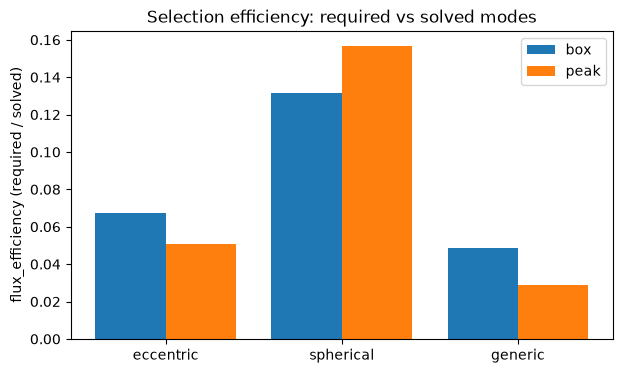

In [3]:
names = [r[0] for r in rows]
xs = np.arange(len(names))
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(xs - 0.2, [r[3] for r in rows], 0.4, label="box")
ax.bar(xs + 0.2, [r[4] for r in rows], 0.4, label="peak")
ax.set_xticks(xs, names); ax.set_ylabel("flux_efficiency (required / solved)")
ax.set_title("Selection efficiency: required vs solved modes"); ax.legend()
plt.show()
# every mode set reproduces its flux; efficiency is a ratio in (0, 1]
for _, _, _, eb, ep, _ in rows:
    assert 0 < eb <= 1 and 0 < ep <= 1

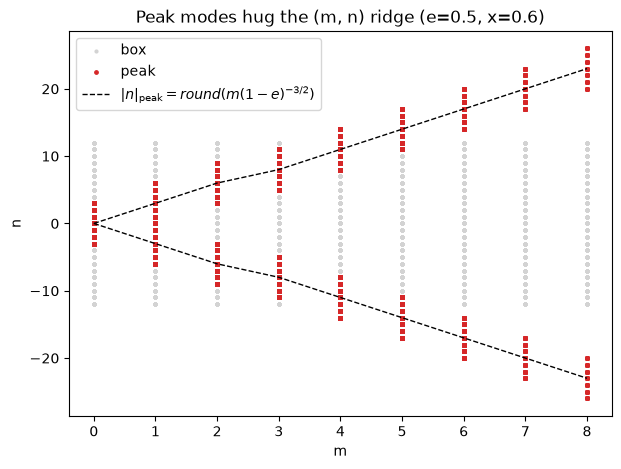

box 12509 vs peak 6968 modes in this window


In [4]:
orb = MiniGeo(0.9, 8.0, 0.5, 0.6)      # eccentric + inclined: ridge departs from n=0
box = set(_window_modes(8, 6, 12))
peak = set(_peak_window_modes(orb, 8, 3, 3))
assert peak <= box or True             # peak may reach beyond a fixed box
# (m, n) scatter at l = m + k slices; show peak hugging the |n| ~ m/(1-e)^1.5 ridge
bm = np.array([(m, n) for (l, m, k, n) in box])
pm = np.array([(m, n) for (l, m, k, n) in peak])
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(bm[:, 0], bm[:, 1], s=4, c="lightgray", label="box")
ax.scatter(pm[:, 0], pm[:, 1], s=6, c="C3", label="peak")
mm = np.arange(0, 9)
ridge = np.array([_n_peak_mag(orb.e, m) for m in mm])
ax.plot(mm, ridge, "k--", lw=1, label=r"$|n|_{\rm peak}=round(m(1-e)^{-3/2})$")
ax.plot(mm, -ridge, "k--", lw=1)
ax.set_xlabel("m"); ax.set_ylabel("n"); ax.legend()
ax.set_title(f"Peak modes hug the (m, n) ridge (e={orb.e}, x={orb.x})")
plt.show()
print(f"box {len(box)} vs peak {len(peak)} modes in this window")